# Model 4 — LightGBM with Optuna

**Question:** can tuning LightGBM improve ranking over its original two settings and simple baselines?

After Notebook 06 has prepared the three folds, select the project kernel and **Restart Kernel and Run All**. Open from the FYP folder or `research/`. Existing prepared inputs can be reused: no need to rerun 01–06 or the other model studies. This notebook contains its own modelling code and does not execute other notebooks or download data. LightGBM and Optuna are already in `requirements.txt`.

**Protocol declared before fitting:** 16 sequential Optuna trials, each scored on all three expanding 2025 folds; maximise unweighted mean average precision (AP), with the earliest trial breaking ties. Tune leaf count, minimum child samples, L2 regularisation and class weighting. Fix 150 boosting rounds, learning rate 0.05, column sampling 0.8, seed 42 and two CPU workers. No pruning, early stopping or random cross-validation. Keep the features, 10% target and coverage rules unchanged. AP means sklearn average precision, not trapezoidal PR-AUC.

**Status:** supplementary exploratory development after earlier results were inspected. Reused folds and January–March 2026 validation are not independent confirmation. No April–June test data or November outcome data are read. The 2025 training set is used here; this is not the separate longer-history dashboard model. Equal trial counts across model studies do not imply equal compute cost or equally exhaustive searches.

Each Run All writes a separate timestamped folder. Other study outputs, prepared inputs, active-run selection and dashboard checkpoints are not replaced. No tuning candidate is automatically promoted to the dashboard.

**Reading guide for the report:** section 1 explains the technique and search; section 4 displays tuning/fold comparisons; section 5 displays later validation and groups; section 6 contains plots/exports; section 7 interprets this model's saved results. Notebook 06 remains the original reference experiment, and research/12 is the separate longer-history study.


## 1. Settings and technique

LightGBM builds gradient-boosted decision trees using histogram-based split finding and leaf-wise growth. The leaf count controls complexity; minimum child samples and regularisation restrict small or overly specialised leaves. Numerical features are median-imputed with missing indicators, and categories are one-hot encoded. No numerical scaling is needed. Preprocessing is fitted using each training fold only.

| Hyperparameter | Search options | Purpose |
|---|---|---|
| `num_leaves` | 15, 31, 63 | Limit the number of leaves per tree. |
| `min_child_samples` | 30, 60, 120 | Minimum data support for a leaf; LightGBM's Hessian-based approximation can occasionally differ from an exact row-count minimum. |
| `reg_lambda` | 0, 1, 5 | L2 regularisation on leaf weights. |
| `class_weight` | `None`, `"balanced"` | Equal sample weights or weights derived from training class frequencies. |

The first two trials reproduce Notebook 06's 15-leaf/31-leaf settings with minimum child samples 30, L2 regularisation 0 and balanced weights. The next two use the same settings without weighting. Balanced weights are calculated from that fit's training labels only. Scores remain uncalibrated, and weighting can change the usefulness of a fixed 0.5 cutoff.

Tree depth remains unlimited (`max_depth=-1`); leaf count and child support constrain complexity. This modest search does not optimise every LightGBM setting. On macOS, a missing `libomp.dylib` requires `brew install libomp` in Terminal before restarting the kernel.

In [1]:
import sys
from pathlib import Path
REPOSITORY_ROOT = Path.cwd()
if not (REPOSITORY_ROOT / "pricecatcher_config.py").is_file():
    REPOSITORY_ROOT = REPOSITORY_ROOT.parent
if not (REPOSITORY_ROOT / "pricecatcher_config.py").is_file():
    raise FileNotFoundError("Open the FYP project folder before running this notebook.")
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

import hashlib
import json
from datetime import datetime, timezone
from importlib import metadata, reload
from time import perf_counter
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import optuna
except ModuleNotFoundError:
    raise ModuleNotFoundError("Install Optuna in this kernel: %pip install 'optuna>=4,<5', then restart and Run All.") from None
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
try:
    import lightgbm as lgb
    from lightgbm import LGBMClassifier
except ModuleNotFoundError:
    raise ModuleNotFoundError("LightGBM is missing in this kernel. Install the repository requirements, then restart and Run All.") from None
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import pricecatcher_config as cfg
cfg = reload(cfg)

SEED = 42
N_TRIALS = 16
TREES = 150
N_JOBS = 2
SEARCH_SPACE = {
    "num_leaves": [15, 31, 63],
    "min_child_samples": [30, 60, 120],
    "reg_lambda": [0.0, 1.0, 5.0],
    "class_weight": [None, "balanced"],
}
REFERENCE_SETTINGS = [
    ("Reference leaves=15", {"num_leaves": 15, "min_child_samples": 30,
                             "reg_lambda": 0.0, "class_weight": "balanced"}),
    ("Reference leaves=31", {"num_leaves": 31, "min_child_samples": 30,
                             "reg_lambda": 0.0, "class_weight": "balanced"}),
    ("Unweighted leaves=15", {"num_leaves": 15, "min_child_samples": 30,
                              "reg_lambda": 0.0, "class_weight": None}),
    ("Unweighted leaves=31", {"num_leaves": 31, "min_child_samples": 30,
                              "reg_lambda": 0.0, "class_weight": None}),
]
FOLDS = ["fold_1", "fold_2", "fold_3"]
print("Python:", sys.executable)
print("Prepared run:", cfg.PROJECT_ROOT)
print("LightGBM:", lgb.__version__)
print("Trials:", N_TRIALS, "| Folds:", len(FOLDS), "| Trees:", TREES, "| Fixed target: 10%")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /usr/local/bin/python3.12
Prepared run: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240
LightGBM: 4.7.0
Trials: 16 | Folds: 3 | Trees: 150 | Fixed target: 10%


## 2. Load and check training/validation inputs only

Use the prepared inputs from the original 2025 experiment, not the longer-history training set. Missing folds must first be prepared through Notebook 06 (or the documented preparation command). This notebook never regenerates frozen inputs. Verify shared policies/source identity and date boundaries before fitting. A legacy source mismatch stops rather than assuming equivalent data.

In [2]:
def file_hash(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

folders = {name: cfg.PROJECT_ROOT / "experiments" / name / "05_modelling"
           for name in FOLDS + ["holdout"]}
input_paths = [folder / filename for folder in folders.values()
               for filename in ["experiment_settings.json", "train.parquet", "validation.parquet"]]
missing = [str(path) for path in input_paths if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing prepared inputs: " + ", ".join(missing)
                            + ". Complete Notebook 06's fold preparation first; do not delete existing data.")
input_hashes = {str(path.relative_to(cfg.PROJECT_ROOT)): file_hash(path) for path in input_paths}
settings_by_fold = {name: json.loads((folder / "experiment_settings.json").read_text())
                    for name, folder in folders.items()}
settings = settings_by_fold["holdout"]
FEATURES = settings["feature_columns"]
NUMERIC = settings["numeric_features"]
CATEGORICAL = settings["categorical_features"]
if len(FEATURES) != len(set(FEATURES)) or sorted(NUMERIC + CATEGORICAL) != sorted(FEATURES):
    raise ValueError("Numeric and categorical features must partition the feature list.")
if any(c.startswith("next_") or c in ["surge_label", "split"] for c in FEATURES):
    raise ValueError("Future outcomes must not enter the model features.")
if settings["surge_threshold_pct"] != 10:
    raise ValueError("This study requires the existing fixed 10% target.")
variable = {"experiment", "train_end", "validation_end", "test_end", "evaluation_end",
            "apply_documented_exclusions", "source_manifest_sha256", "source_snapshot_sha256"}
policy = {k: v for k, v in settings["preparation"].items() if k not in variable}
source_key = ("source_snapshot_sha256" if settings["preparation"].get("source_snapshot_sha256")
              else "source_manifest_sha256")
source_id = settings["preparation"].get(source_key)
if not source_id:
    raise ValueError("Source identity is missing; restore matching preparation metadata.")

frames = {}
for name, folder in folders.items():
    s = settings_by_fold[name]
    if tuple(s[k] for k in ["train_end", "validation_end", "test_end"]) != tuple(cfg.EXPERIMENTS[name]):
        raise ValueError(f"{name}: date settings differ from the configured chronological experiment.")
    for key in ["feature_columns", "numeric_features", "categorical_features", "target_status", "surge_threshold_pct"]:
        if s[key] != settings[key]:
            raise ValueError(f"{name}: incompatible {key}.")
    if ({k: v for k, v in s["preparation"].items() if k not in variable} != policy
            or s["preparation"].get(source_key) != source_id
            or s["preparation"].get("experiment") != name):
        raise ValueError(f"{name}: shared source/policies differ. Restore consistent prepared inputs.")
    if name in FOLDS and s["preparation"].get("apply_documented_exclusions"):
        raise ValueError("Early folds must retain retrospective exceptions whose review dates are unknown.")
    frames[name] = {}
    for split in ["train", "validation"]:
        frame = pd.read_parquet(folder / f"{split}.parquet")
        required = FEATURES + ["surge_label", "week_start", "next_week_end", "project_group"]
        if frame.empty or set(required) - set(frame.columns):
            raise ValueError(f"{name}/{split}: empty or incomplete input.")
        if frame.surge_label.isna().any() or not frame.surge_label.isin([0, 1]).all() or frame.surge_label.nunique() != 2:
            raise ValueError(f"{name}/{split}: overall evaluation requires both observed classes.")
        for col in ["week_start", "next_week_end"]:
            frame[col] = pd.to_datetime(frame[col])
        if (frame[["week_start", "next_week_end"]].isna().any().any()
                or not frame.week_start.dt.dayofweek.eq(0).all()
                or not frame.next_week_end.eq(frame.week_start + pd.Timedelta(days=13)).all()):
            raise ValueError(f"{name}/{split}: invalid calendar-week horizons.")
        upper = pd.Timestamp(s["train_end" if split == "train" else "validation_end"])
        if not frame.next_week_end.le(upper).all():
            raise ValueError(f"{name}/{split}: outcome crosses its time boundary.")
        if split == "validation" and not (frame.week_start + pd.Timedelta(days=6)).gt(pd.Timestamp(s["train_end"])).all():
            raise ValueError(f"{name}: validation overlaps training.")
        if frame.duplicated(["item_code", "state", "district", "premise_type", "week_start"]).any():
            raise ValueError(f"{name}/{split}: duplicate local series/week.")
        if np.isinf(frame[NUMERIC].to_numpy(dtype=float)).any():
            raise ValueError(f"{name}/{split}: infinite numeric input.")
        frames[name][split] = frame

display(pd.DataFrame([{"experiment": name, "train_end": s["train_end"],
                      "validation_end": s["validation_end"],
                      "training_rows": len(frames[name]["train"]),
                      "validation_rows": len(frames[name]["validation"])}
                     for name, s in settings_by_fold.items()]))

,experiment,train_end,validation_end,training_rows,validation_rows
0,fold_1,2025-05-31,2025-07-31,66384,31971
1,fold_2,2025-07-31,2025-09-30,101515,31753
2,fold_3,2025-09-30,2025-12-31,138296,54666
3,holdout,2025-12-31,2026-03-31,195664,43594


## 3. Pipeline, metrics and baselines

Each fit uses a fresh preprocessor and estimator. Classification comparisons use the common 0.5 reference cutoff; AP selects parameters independently of that cutoff. AP and F1 at a fixed cutoff measure different aspects of performance.

The current-change baseline ranks by the observed weekly percentage change and alerts at 10%, following the saved label tolerance. The no-surge baseline always predicts zero. Positive-case metrics remain missing for groups without surges; precision is recorded as zero when there are no alerts.

In [3]:
def model_inputs(frame):
    X = frame[FEATURES].copy()
    for column in CATEGORICAL:
        X[column] = X[column].astype("string").fillna("__missing__").astype(str)
    return X


def build_pipeline(parameters):
    numeric = SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    preprocessing = ColumnTransformer([
        ("numeric", numeric, NUMERIC),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CATEGORICAL),
    ], sparse_threshold=1.0)
    model = LGBMClassifier(n_estimators=TREES, learning_rate=0.05, colsample_bytree=0.8,
                           max_depth=-1, objective="binary", verbosity=-1,
                           random_state=SEED, n_jobs=N_JOBS, **parameters)
    return Pipeline([("preprocess", preprocessing), ("model", model)])


def fit_and_score(parameters, training, evaluation):
    pipeline = build_pipeline(parameters)
    pipeline.fit(model_inputs(training), training.surge_label.astype(int))
    scores = pipeline.predict_proba(model_inputs(evaluation))[:, 1]
    if not np.isfinite(scores).all() or not ((scores >= 0) & (scores <= 1)).all():
        raise ValueError("Model scores must be finite and in [0, 1].")
    return pipeline, scores


def evaluate(y, scores, predictions):
    y, scores, predictions = np.asarray(y, dtype=int), np.asarray(scores), np.asarray(predictions, dtype=int)
    if not len(y) or len(y) != len(scores) or len(y) != len(predictions) or not np.isfinite(scores).all():
        raise ValueError("Metrics require aligned nonempty arrays and finite scores.")
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[0, 1]).ravel()
    return {"rows": len(y), "positives": int(y.sum()), "alerts": int(predictions.sum()),
            "average_precision": float(average_precision_score(y, scores)) if len(np.unique(y)) == 2 else np.nan,
            "precision": float(precision_score(y, predictions, zero_division=0)),
            "recall": float(recall_score(y, predictions, zero_division=0)) if y.sum() else np.nan,
            "f1": float(f1_score(y, predictions, zero_division=0)) if y.sum() else np.nan,
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}


def baselines(frame):
    change = frame.weekly_price_change_pct.to_numpy(dtype=float)
    if not np.isfinite(change).all():
        raise ValueError("Current-change baseline requires supported previous-week prices.")
    tolerance = settings["preparation"].get("label_tolerance_pct", 0.0)
    alerts = (change >= 10) | np.isclose(change, 10, atol=tolerance, rtol=0)
    return {"Always no surge": (np.zeros(len(frame)), np.zeros(len(frame), dtype=int)),
            "Current-change rule": (change, alerts.astype(int))}

## 4. Optuna search on the 2025 folds

Seeded TPE proposes the four hyperparameters together. All trials use every fold and the same eligible rows. The four queued references ensure both weighting choices are evaluated. In result tables, `none` means Python `None`, preventing unweighted rows from disappearing in grouped summaries. Saved model parameters retain their actual Python/JSON values.

Record fit time alongside the 16-trial/48-fold-fit budget. Fixed boosting rounds and no early stopping keep the fitting protocol consistent. A higher maximum search score is not an independent improvement estimate because the search explicitly selects that score.

In [4]:
trial_fold_rows = []

def objective(trial):
    parameters = {name: trial.suggest_categorical(name, choices)
                  for name, choices in SEARCH_SPACE.items()}
    aps = []
    for name in FOLDS:
        training, evaluation = frames[name]["train"], frames[name]["validation"]
        started = perf_counter()
        pipeline, scores = fit_and_score(parameters, training, evaluation)
        metrics = evaluate(evaluation.surge_label, scores, scores >= 0.5)
        trial_fold_rows.append({"trial": trial.number, **parameters,
                               "class_weight": parameters["class_weight"] or "none", "fold": name,
                               "fit_and_score_seconds": perf_counter() - started, **metrics})
        aps.append(metrics["average_precision"])
        del pipeline
    return float(np.mean(aps))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.NopPruner())
for label, parameters in REFERENCE_SETTINGS:
    study.enqueue_trial(parameters)
study.optimize(objective, n_trials=N_TRIALS, n_jobs=1)
best_trial = max(study.trials, key=lambda trial: (trial.value, -trial.number))
BEST_PARAMETERS = best_trial.params
trial_folds = pd.DataFrame(trial_fold_rows)
trial_summary = trial_folds.groupby("trial", as_index=False).agg(
    num_leaves=("num_leaves", "first"), min_child_samples=("min_child_samples", "first"),
    reg_lambda=("reg_lambda", "first"), class_weight=("class_weight", "first"),
    mean_ap=("average_precision", "mean"), std_ap=("average_precision", "std"),
    mean_f1_at_05=("f1", "mean"), mean_precision_at_05=("precision", "mean"),
    mean_recall_at_05=("recall", "mean"), total_fit_and_score_seconds=("fit_and_score_seconds", "sum"))
display(trial_summary.sort_values(["mean_ap", "trial"], ascending=[False, True]))
print("Selected parameters:", BEST_PARAMETERS, "| Mean fold AP:", best_trial.value)

comparison_rows = []
reference_trials = [(label, number) for number, (label, _) in enumerate(REFERENCE_SETTINGS)]
for label, trial_number in reference_trials + [("Optuna selected", best_trial.number)]:
    for row in trial_fold_rows:
        if row["trial"] == trial_number:
            comparison_rows.append({"method": label, **row})
for name in FOLDS:
    evaluation = frames[name]["validation"]
    for label, (scores, predictions) in baselines(evaluation).items():
        comparison_rows.append({"method": label, "fold": name,
                                **evaluate(evaluation.surge_label, scores, predictions)})
fold_comparison = pd.DataFrame(comparison_rows)
fold_summary = fold_comparison.groupby("method").agg(
    mean_ap=("average_precision", "mean"), std_ap=("average_precision", "std"),
    mean_precision=("precision", "mean"), mean_recall=("recall", "mean"), mean_f1=("f1", "mean"))
display(fold_summary)

[I 2026-10-27 16:43:53,450] A new study created in memory with name: no-name-38aa3ec1-f0f2-4238-96a9-8087b914ecc9
[I 2026-10-27 16:43:56,936] Trial 0 finished with value: 0.3509690712782603 and parameters: {'num_leaves': 15, 'min_child_samples': 30, 'reg_lambda': 0.0, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.3509690712782603.
[I 2026-10-27 16:44:00,703] Trial 1 finished with value: 0.35572022956490396 and parameters: {'num_leaves': 31, 'min_child_samples': 30, 'reg_lambda': 0.0, 'class_weight': 'balanced'}. Best is trial 1 with value: 0.35572022956490396.
[I 2026-10-27 16:44:03,661] Trial 2 finished with value: 0.3540844339881821 and parameters: {'num_leaves': 15, 'min_child_samples': 30, 'reg_lambda': 0.0, 'class_weight': None}. Best is trial 1 with value: 0.35572022956490396.
[I 2026-10-27 16:44:07,316] Trial 3 finished with value: 0.3576637599451848 and parameters: {'num_leaves': 31, 'min_child_samples': 30, 'reg_lambda': 0.0, 'class_weight': None}. Best is trial 3

,trial,num_leaves,min_child_samples,reg_lambda,class_weight,mean_ap,std_ap,mean_f1_at_05,mean_precision_at_05,mean_recall_at_05,total_fit_and_score_seconds
10,10,63,60,5.0,none,0.359971,0.066703,0.192400,0.530430,0.129922,4.832440
11,11,63,60,5.0,none,0.359971,0.066703,0.192400,0.530430,0.129922,4.856297
12,12,63,60,5.0,none,0.359971,0.066703,0.192400,0.530430,0.129922,5.067789
13,13,63,60,5.0,none,0.359971,0.066703,0.192400,0.530430,0.129922,4.917234
14,14,63,60,5.0,none,0.359971,0.066703,0.192400,0.530430,0.129922,4.916609
15,15,63,60,5.0,none,0.359971,0.066703,0.192400,0.530430,0.129922,4.970327
6,6,63,30,5.0,none,0.358483,0.061266,0.187155,0.534942,0.128588,4.822207
3,3,31,30,0.0,none,0.357664,0.068306,0.170291,0.552899,0.116845,3.652564
1,1,31,30,0.0,balanced,0.355720,0.061089,0.393061,0.282302,0.669978,3.765080
7,7,31,120,5.0,balanced,0.354865,0.056413,0.392755,0.283487,0.663764,3.801642


Selected parameters: {'num_leaves': 63, 'min_child_samples': 60, 'reg_lambda': 5.0, 'class_weight': None} | Mean fold AP: 0.35997050081011395


,mean_ap,std_ap,mean_precision,mean_recall,mean_f1
method,,,,,
Always no surge,0.106114,0.010602,0.000000,0.000000,0.000000
Current-change rule,0.120974,0.026823,0.189686,0.193252,0.191330
Optuna selected,0.359971,0.066703,0.530430,0.129922,0.192400
Reference leaves=15,0.350969,0.051133,0.266478,0.685167,0.380040
Reference leaves=31,0.355720,0.061089,0.282302,0.669978,0.393061
Unweighted leaves=15,0.354084,0.066488,0.573158,0.098466,0.148267
Unweighted leaves=31,0.357664,0.068306,0.552899,0.116845,0.170291


## 5. Separate exploratory validation: January–March 2026

Fit each LightGBM setting on the same training rows through December 2025. Compare AP and classification metrics at the common 0.5 reference cutoff. This validation period has already been inspected in earlier work; do not treat it as a fresh test.

Also choose an F1-maximising cutoff for the Optuna candidate on this validation period, breaking ties with the highest cutoff. Its resulting classification metrics are **apparent cutoff-selection performance**, not an independent estimate. Do not select the best model again using this table. The saved candidate is not promoted to the dashboard.

In [5]:
training = frames["holdout"]["train"]
validation = frames["holdout"]["validation"]
validation_rows = []
validation_scores = {}
for label, parameters in REFERENCE_SETTINGS + [("Optuna selected", BEST_PARAMETERS)]:
    pipeline, scores = fit_and_score(parameters, training, validation)
    validation_scores[label] = scores
    validation_rows.append({"method": label, **parameters,
                            "class_weight": parameters["class_weight"] or "none", "cutoff": 0.5,
                            **evaluate(validation.surge_label, scores, scores >= 0.5)})
    if label == "Optuna selected":
        selected_pipeline = pipeline
for label, (scores, predictions) in baselines(validation).items():
    validation_rows.append({"method": label, **evaluate(validation.surge_label, scores, predictions)})
selected_scores = validation_scores["Optuna selected"]
precision, recall, cutoffs = precision_recall_curve(validation.surge_label, selected_scores)
f1 = np.divide(2 * precision[:-1] * recall[:-1], precision[:-1] + recall[:-1],
               out=np.zeros(len(cutoffs)), where=(precision[:-1] + recall[:-1]) > 0)
selected_cutoff = float(cutoffs[np.flatnonzero(np.isclose(f1, f1.max(), atol=1e-12, rtol=0))[-1]])
validation_rows.append({"method": "Optuna selected: apparent cutoff-selection performance",
                        **BEST_PARAMETERS, "class_weight": BEST_PARAMETERS["class_weight"] or "none",
                        "cutoff": selected_cutoff,
                        **evaluate(validation.surge_label, selected_scores, selected_scores >= selected_cutoff)})
validation_comparison = pd.DataFrame(validation_rows)
display(validation_comparison)
group_rows = []
for group, positions in validation.groupby("project_group", sort=True).indices.items():
    group_rows.append({"project_group": group,
        **evaluate(validation.iloc[positions].surge_label, selected_scores[positions],
                    selected_scores[positions] >= selected_cutoff)})
group_comparison = pd.DataFrame(group_rows)
display(group_comparison)
print("These group metrics also reuse the cutoff-selection period, not an untouched test.")

,method,num_leaves,min_child_samples,reg_lambda,class_weight,cutoff,rows,positives,alerts,average_precision,precision,recall,f1,tp,fp,fn,tn
0,Reference leaves=15,15.0,30.0,0.0,balanced,0.500000,43594,3912,16634,0.228754,0.197307,0.838957,0.319478,3282,13352,630,26330
1,Reference leaves=31,31.0,30.0,0.0,balanced,0.500000,43594,3912,15746,0.223372,0.203099,0.817485,0.325364,3198,12548,714,27134
2,Unweighted leaves=15,15.0,30.0,0.0,none,0.500000,43594,3912,1741,0.221722,0.218265,0.097137,0.134442,380,1361,3532,38321
3,Unweighted leaves=31,31.0,30.0,0.0,none,0.500000,43594,3912,2063,0.226419,0.213282,0.112474,0.147280,440,1623,3472,38059
4,Optuna selected,63.0,60.0,5.0,none,0.500000,43594,3912,2589,0.216171,0.200850,0.132924,0.159975,520,2069,3392,37613
5,Always no surge,NaN,NaN,NaN,NaN,NaN,43594,3912,0,0.089737,0.000000,0.000000,0.000000,0,0,3912,39682
6,Current-change rule,NaN,NaN,NaN,NaN,NaN,43594,3912,4417,0.101561,0.175685,0.198364,0.186337,776,3641,3136,36041
7,Optuna selected: apparent cutoff-selection per...,63.0,60.0,5.0,none,0.159058,43594,3912,11282,0.216171,0.228860,0.660020,0.339871,2582,8700,1330,30982


,project_group,rows,positives,alerts,average_precision,precision,recall,f1,tp,fp,fn,tn
0,Chicken,4884,25,84,0.161804,0.130952,0.440000,0.201835,11,73,14,4786
1,Cooking Oil,2178,1,0,0.000544,0.000000,0.000000,0.000000,0,0,1,2177
2,Eggs,8892,53,58,0.108999,0.155172,0.169811,0.162162,9,49,44,8790
3,Flour,1110,15,18,0.294499,0.388889,0.466667,0.424242,7,11,8,1084
4,Rice,384,2,1,0.571429,1.000000,0.500000,0.666667,1,0,1,382
5,Sugar,1837,0,0,NaN,0.000000,NaN,NaN,0,0,0,1837
6,Vegetables,24309,3816,11121,0.217553,0.229656,0.669287,0.341970,2554,8567,1262,11926


These group metrics also reuse the cutoff-selection period, not an untouched test.


## 6. Plots and saved evidence

The plots show search behaviour and validation ranking. The horizontal prevalence reference represents constant-score AP. No plot establishes future reliability. Each new execution saves a separate study; interrupted executions do not publish a completed manifest.

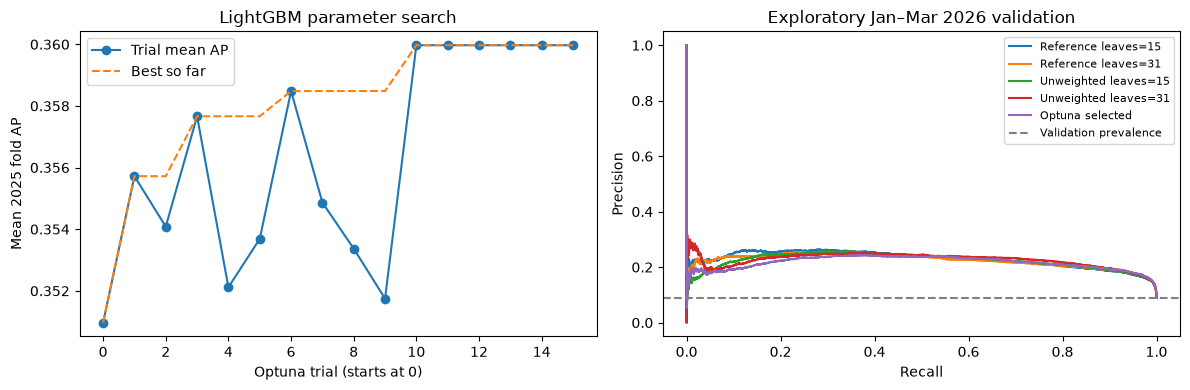

Saved separate research outputs: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/18_lightgbm_optuna/20261027_084509_879755
Original models, dashboard and active-run selection were not replaced.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ordered = trial_summary.sort_values("trial")
axes[0].plot(ordered.trial, ordered.mean_ap, "o-", label="Trial mean AP")
axes[0].plot(ordered.trial, ordered.mean_ap.cummax(), "--", label="Best so far")
axes[0].set(xlabel="Optuna trial (starts at 0)", ylabel="Mean 2025 fold AP", title="LightGBM parameter search")
axes[0].legend()
for label, scores in validation_scores.items():
    p, r, _ = precision_recall_curve(validation.surge_label, scores)
    axes[1].plot(r, p, label=label)
axes[1].axhline(validation.surge_label.mean(), color="grey", linestyle="--", label="Validation prevalence")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Exploratory Jan–Mar 2026 validation")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

# Recheck exact inputs before publishing this separate result folder.
if any(file_hash(cfg.PROJECT_ROOT / name) != digest for name, digest in input_hashes.items()):
    raise ValueError("Prepared inputs changed during tuning. No completed result is published.")
stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
OUTPUT_DIR = cfg.PROJECT_ROOT / "18_lightgbm_optuna" / stamp
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
for filename, table in {
    "trial_fold_metrics.csv": trial_folds, "trial_summary.csv": trial_summary,
    "fold_comparison.csv": fold_comparison, "fold_summary.csv": fold_summary.reset_index(),
    "validation_comparison.csv": validation_comparison, "validation_group_metrics.csv": group_comparison,
}.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)
study.trials_dataframe().to_csv(OUTPUT_DIR / "optuna_trials.csv", index=False)
fig.savefig(OUTPUT_DIR / "tuning_and_validation.png", dpi=160, bbox_inches="tight")
joblib.dump(selected_pipeline, OUTPUT_DIR / "lightgbm.joblib")
selection = {"family": "LightGBM", "parameters": BEST_PARAMETERS,
             "fixed_parameters": {"n_estimators": TREES, "learning_rate": 0.05, "colsample_bytree": 0.8,
                                  "max_depth": -1, "objective": "binary", "verbosity": -1},
             "seed": SEED, "n_jobs": N_JOBS, "trials": N_TRIALS,
             "search": SEARCH_SPACE,
             "reference_settings": [{"method": label, "parameters": parameters}
                                    for label, parameters in REFERENCE_SETTINGS],
             "selection_metric": "mean AP over three expanding 2025 folds; earliest trial breaks ties",
             "selected_trial": best_trial.number, "score_cutoff": selected_cutoff,
             "cutoff_rule": "maximum Jan–Mar validation F1; highest cutoff breaks ties",
             "feature_columns": FEATURES, "surge_threshold_pct": 10.0,
             "training_end": settings["train_end"], "validation_end": settings["validation_end"],
             "refit_on_validation": False, "score_interpretation": "uncalibrated model score"}
(OUTPUT_DIR / "selection.json").write_text(json.dumps(selection, indent=2))
manifest = {"status": "completed", "study_status": "supplementary exploratory tuning; test not accessed",
            "input_sha256": input_hashes, "selection": selection,
            "preparation": {name: s["preparation"] for name, s in settings_by_fold.items()},
            "package_versions": {p: metadata.version(p) for p in ["optuna", "lightgbm", "pandas", "numpy", "scikit-learn", "joblib"]},
            "notebook_sha256": file_hash(REPOSITORY_ROOT / "research" / "18_lightgbm_optuna.ipynb"),
            "output_sha256": {p.name: file_hash(p) for p in OUTPUT_DIR.iterdir() if p.is_file()}}
(OUTPUT_DIR / "study_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Saved separate research outputs:", OUTPUT_DIR)
print("Original models, dashboard and active-run selection were not replaced.")

## 7. Implementation and results notes for the report

**Evidence snapshot:** these notes describe the saved local execution reviewed on **27 October 2026**. They are explanatory Markdown, not new calculations. If a later reproduction changes the outputs, update these historical notes before quoting them as current results. Model selection, code and saved outputs were not changed by adding this explanation.

### 7.1 How LightGBM was implemented

LightGBM is another gradient-boosted tree method. Its binary score can be written schematically as:

$$F_M(x)=b+\eta\sum_{m=1}^{M}f_m(x),\qquad s(x)=\sigma(F_M(x)).$$

This study fixes $M=150$ and $\eta=0.05$. LightGBM uses histogram-based splitting and leaf-wise growth: it chooses a leaf split offering a large objective improvement, subject to constraints. Its mechanism differs from averaging independently bootstrapped Random Forest trees.

`num_leaves` limits tree complexity, `min_child_samples` restricts leaf support, and `reg_lambda` penalises leaf weights. Class weighting is either absent or derived from the training labels. Depth stays unlimited while leaf count and support constrain growth. Imputation and category encoding are fitted within each training fold; no numerical scaling is used. Section 1 lists the searched values and fixed settings. These settings are distinct from the longer-history dashboard checkpoint.

All 16 trials are sequential proposals from seeded Optuna TPE. Each proposal is fitted independently on the three expanding 2025 folds, including a fresh preprocessor. The objective is mean fold AP, not accuracy or F1. Four queued references include the original two weighted settings and their unweighted counterparts. A trial is an evaluation attempt, not necessarily a unique configuration; the saved search contains repeated proposals. Keep the actual trial history rather than claiming 16 distinct configurations.

### 7.2 Selected configuration

| Parameter | Selected value |
|---|---|
| `num_leaves` | 63 |
| `min_child_samples` | 60 |
| `reg_lambda` | 5.0 |
| `class_weight` | None (unweighted) |

The selected setting maximised the declared mean-fold AP objective. Its score cutoff was chosen separately on January–March 2026 validation; changing this cutoff does not alter the 10% price-rise definition.

### 7.3 Evidence of predictive performance

| Method | Mean 2025 fold AP | Fold AP standard deviation | Jan–Mar 2026 validation AP |
|---|---:|---:|---:|
| Always no surge | 0.1061 | 0.0106 | 0.0897 |
| Current-change rule | 0.1210 | 0.0268 | 0.1016 |
| Reference leaves=15 | 0.3510 | 0.0511 | 0.2288 |
| Reference leaves=31 | 0.3557 | 0.0611 | 0.2234 |
| Optuna selected | 0.3600 | 0.0667 | 0.2162 |

The constant no-surge score has AP equal to prevalence when both classes are present; this does not mean it detects surges. Its precision/recall/F1 under the no-alert rule are zero here. AP is sklearn average precision, not trapezoidal PR-AUC. Fold standard deviation describes temporal variation, not a confidence interval or significance test.

**Interpretation:** Mean fold AP increased from 0.3557 for the original 31-leaf reference to 0.3600, but later validation AP fell from 0.2234 to 0.2162. It was also below the original 15-leaf reference (0.2288). Higher tuning AP therefore did not establish better later-period performance. This 2025-trained candidate is not the separate 2024–2025 longer-history dashboard model.

### 7.4 What the alert cutoff changes

Both rows below use the same selected fitted model and the same **43,594 validation rows**, containing **3,912 surges**. AP is unchanged by moving the cutoff.

| Operating point | Cutoff | Precision | Recall | F1 | Alerts | Correct alerts | False alerts | Missed surges |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Common reference | 0.5000 | 20.1% | 13.3% | 0.1600 | 2,589 | 520 | 2,069 | 3,392 |
| Validation-selected | 0.1591 | 22.9% | 66.0% | 0.3399 | 11,282 | 2,582 | 8,700 | 1,330 |

The selected cutoff maximises F1 on this same validation period, with the highest cutoff breaking ties. These are **apparent cutoff-selection metrics**, not independent test estimates. 77.1% of selected-cutoff alerts were false. The score is uncalibrated; the cutoff is not a verified event probability or a percentage price increase.

### 7.5 Food groups and limitations

Vegetables contribute 2,554 of 2,582 correct alerts. Chicken recall is 44.0% (11/25), eggs 17.0% (9/53), and flour 46.7% (7/15). Cooking oil has one positive and rice two, limiting conclusions; sugar has no positives, so its positive-case recall and F1 remain undefined.

Overall metrics therefore need group support and recall alongside them. SHAP contributions do not establish economic causes, and this experiment does not demonstrate affordability or stakeholder-adoption benefits. The data were prepared using the existing documented source/coverage rules, so unresolved source quality and changing observation composition remain limitations.

### 7.6 How to explain the result in your report

**Implementation chapter:** describe the technique above, training-fitted preprocessing, parameter ranges in section 1, fixed settings, class-weight policy, 16-trial search, chronological folds and AP objective. Cite appropriate methodological references for the algorithm and Optuna; this notebook is implementation evidence, not a substitute for those references.

**Results chapter:** use section 7.3 for reference-versus-tuned ranking, section 7.4 for the alert trade-off, and the displayed group table for support and uneven performance. Explain both gains and weaknesses; do not report only the largest score. A fitting-time field includes fitting and scoring, not just estimator training.

**Conclusion:** The largest mean fold AP among the four selected candidates did not translate into the strongest later validation ranking. The result provides no independent basis for replacing the separate longer-history dashboard checkpoint. Retaining or replacing a dashboard checkpoint is a separate operational decision; this exploratory study does not automatically replace it.

**Evidence files:** `trial_summary.csv` and `optuna_trials.csv` record the search; `trial_fold_metrics.csv` and `fold_comparison.csv` contain per-fold evidence; `fold_summary.csv` aggregates folds; `validation_comparison.csv` and `validation_group_metrics.csv` support later-period discussion. `selection.json` records parameters/cutoff and `study_manifest.json` records exact inputs, package versions and output hashes. Use those hashes to establish matching datasets across models; equal dates and row counts alone are insufficient.

The original April–June 2026 test has been inspected and is not evaluated here. Neither these validation figures nor another model's original test scores establish this candidate's independent test performance. Further final claims need a genuinely untouched period and a frozen protocol. Do not retune or change the selection because these later results are visible.
